# Encontro 5 — Dinâmica de sistemas

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lambdageo-edu/curso-modelagem-dinamica-espacial/blob/main/docs/notebooks/encontro05_dinamica_sistemas.ipynb)

Sem Python instalado? O selo acima abre este notebook no Google Colab, no navegador. Lá, use *Arquivo → Salvar uma cópia no Drive* antes de mudar qualquer coisa: sem a cópia, o que você escrever se perde ao fechar a página.

Dinâmica de sistemas descreve o mundo como **estoques** (o que se acumula: água, floresta, pessoas) e **fluxos** (o que entra e sai a cada passo). Ainda não há espaço: cada modelo é um único lugar. O espaço chega no próximo encontro, com os autômatos celulares.

Rode as células na ordem. Nas células marcadas com 🔧 você troca um número e roda de novo; nas marcadas com ✏️ você responde.

Ao final, você deve saber:

1. Identificar estoques, fluxos e parâmetros num modelo.
2. Reconhecer retroalimentação de reforço e de equilíbrio.
3. Encontrar o equilíbrio de um modelo pela conta e pela simulação.
4. Comparar uma simulação do DisSModel com a do TerraME.

## 0. Preparação

No Colab, a célula abaixo instala o DisSModel e o pacote de dinâmica de sistemas (cerca de 1 minuto). No laboratório o ambiente já está instalado e ela não instala nada.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q "dissmodel==0.6.6" "dissmodel-sysdyn @ git+https://github.com/DisSModel/dissmodel-sysdyn.git@v0.2.0"

import contextlib, io
import pandas as pd
import matplotlib.pyplot as plt
from dissmodel.core import Environment, Model
from dissmodel_sysdyn.models import Tub, SIR, PredatorPrey

A função abaixo roda um modelo por um número de passos e **anota numa tabela** o valor das variáveis no início e depois de cada passo. Você só vai usá-la; não precisa mudar nada.

In [2]:
def simular(Modelo, passos, variaveis, **parametros):
    """Roda `Modelo` por `passos` passos e devolve uma tabela com as `variaveis`."""
    env = Environment(start_time=1, end_time=passos)
    modelo = Modelo(**parametros)
    linhas = [{"passo": 0, **{v: getattr(modelo, v) for v in variaveis}}]

    class Anotador(Model):              # roda depois do modelo, a cada passo
        def execute(self):
            linhas.append({"passo": self.env.now(), **{v: getattr(modelo, v) for v in variaveis}})

    Anotador()
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return pd.DataFrame(linhas).set_index("passo")

## 1. Um estoque, um fluxo: a banheira

A banheira começa com 40 litros e perde 5 litros por passo. Opcionalmente, recebe uma quantidade de água a cada tantos passos.

| Elemento | No modelo |
|---|---|
| Estoque | `water` (água na banheira) |
| Fluxo de saída | `out_flow` por passo |
| Fluxo de entrada | `in_flow`, a cada `in_period` passos |

In [3]:
banheira = simular(Tub, passos=20, variaveis=["water"], water=40, out_flow=5)
banheira.head(10)

,water
passo,
0,40.0
1,35.0
2,30.0
3,25.0
4,20.0
5,15.0
6,10.0
7,5.0
8,0.0


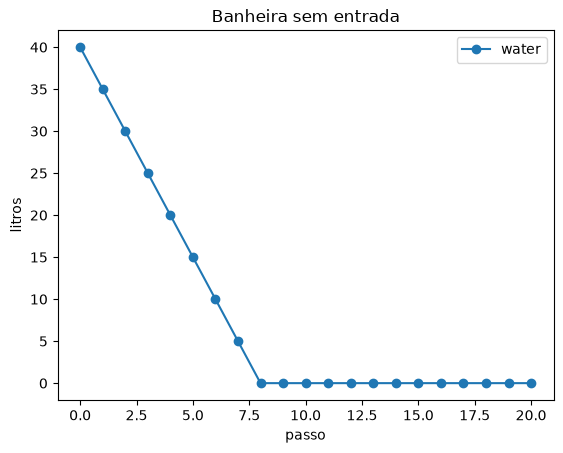

In [4]:
banheira.plot(marker="o", title="Banheira sem entrada", ylabel="litros");

O relógio do DisSModel funciona como o do TerraME: `Environment(start_time=1, end_time=20)` executa os passos 1, 2, …, 20 (o último **inclusive**). A linha `passo 0` é o estado antes do primeiro passo.

🔧 **Agora com entrada:** a cada 10 passos entram 20 litros. Troque `in_flow` e `in_period` e veja o que acontece.

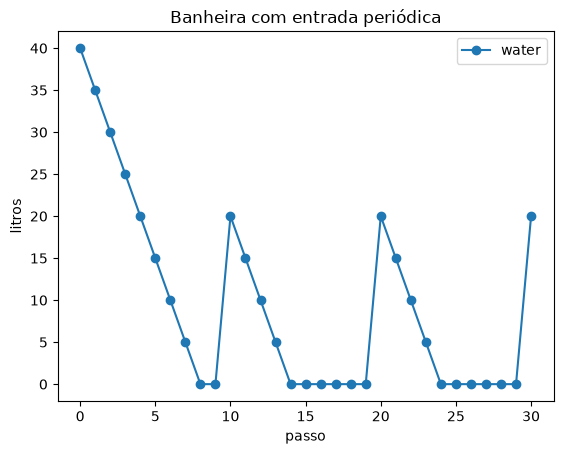

In [5]:
banheira2 = simular(Tub, passos=30, variaveis=["water"],
                    water=40, out_flow=5, in_flow=20, in_period=10)
banheira2.plot(marker="o", title="Banheira com entrada periódica", ylabel="litros");

✏️ **Pergunta 1.** Com `out_flow=5` e `in_period=10`, que valor de `in_flow` faz o nível voltar ao mesmo ponto a cada 10 passos, num ciclo que se repete? Calcule antes (quanto sai em 10 passos?) e confirme rodando.

## 2. Seu primeiro modelo: floresta e desmatamento

Um modelo do DisSModel é uma classe com dois métodos:

- `setup`: guarda os valores iniciais e os parâmetros (roda uma vez);
- `execute`: o que acontece a cada passo.

Neste modelo, a cada ano uma **fração** da floresta é desmatada e uma área **fixa** se regenera.

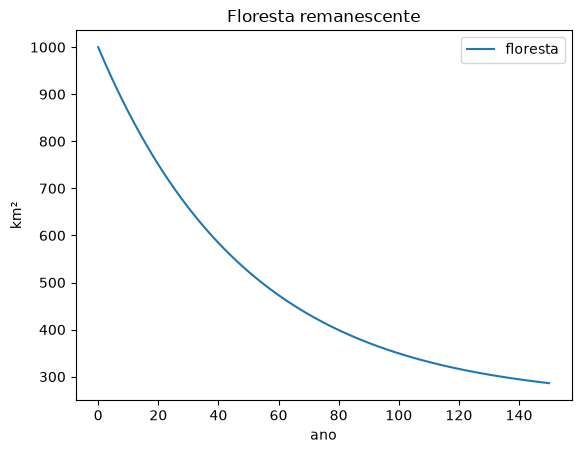

In [6]:
class Floresta(Model):
    def setup(self, floresta=1000.0, taxa_desmatamento=0.02, regeneracao=5.0):
        self.floresta = floresta                      # estoque (km²)
        self.taxa_desmatamento = taxa_desmatamento    # fração desmatada por ano
        self.regeneracao = regeneracao                # km² que voltam por ano

    def execute(self):
        desmatado = self.taxa_desmatamento * self.floresta   # fluxo de saída
        self.floresta = self.floresta - desmatado + self.regeneracao


floresta = simular(Floresta, passos=150, variaveis=["floresta"])
floresta.plot(title="Floresta remanescente", ylabel="km²", xlabel="ano");

A floresta não vai a zero: ela para num valor. É o **equilíbrio**, o ponto em que o que sai é igual ao que entra:

taxa × floresta = regeneração  →  floresta = regeneração / taxa = 5 / 0,02 = **250 km²**

🔧 Comece com `floresta=100` (menos que o equilíbrio). O que acontece?

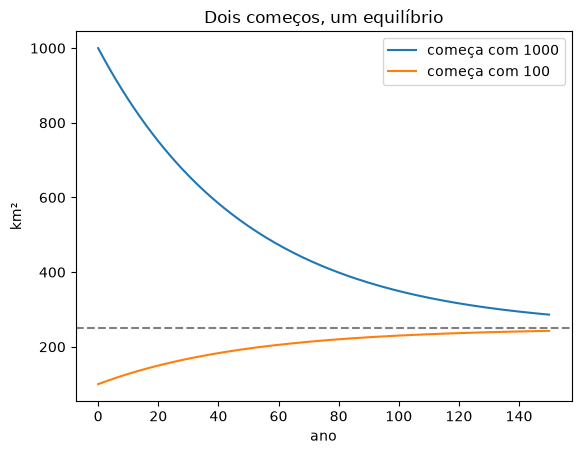

In [7]:
comparacao = pd.DataFrame({
    "começa com 1000": simular(Floresta, 150, ["floresta"], floresta=1000)["floresta"],
    "começa com 100":  simular(Floresta, 150, ["floresta"], floresta=100)["floresta"],
})
ax = comparacao.plot(title="Dois começos, um equilíbrio", ylabel="km²", xlabel="ano")
ax.axhline(5 / 0.02, color="gray", linestyle="--");

✏️ **Pergunta 2.** Uma política reduz a taxa de desmatamento de 2% para 1% ao ano. Qual o novo equilíbrio? Calcule e confirme mudando `taxa_desmatamento`. Quanto tempo leva para chegar perto dele?

## 3. Retroalimentação: uma epidemia (SIR)

A população se divide em três estoques: **S**uscetíveis, **I**nfectados e **R**ecuperados. A cada passo:

- novos infectados = infectados × contatos × probabilidade × (fração de suscetíveis);
- novos recuperados = infectados / duração.

Há duas retroalimentações. Quanto mais infectados, mais novos infectados (**reforço**). Quanto menos suscetíveis restam, mais devagar a doença avança (**equilíbrio**).

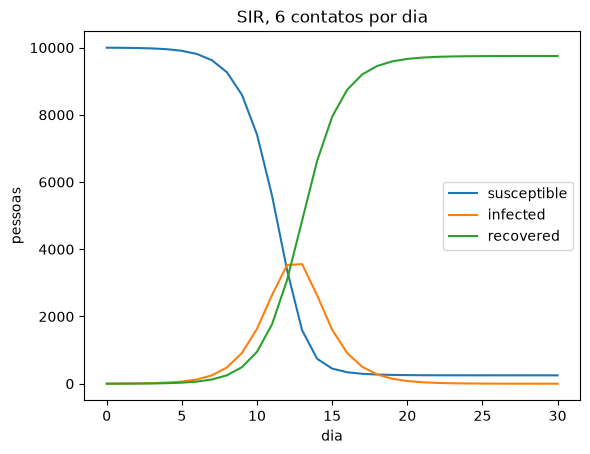

In [8]:
variaveis_sir = ["susceptible", "infected", "recovered"]
sir = simular(SIR, passos=30, variaveis=variaveis_sir, contacts=6)
sir.plot(title="SIR, 6 contatos por dia", ylabel="pessoas", xlabel="dia");

🔧 **Distanciamento:** compare 6, 4 e 3 contatos por dia, agora em 100 dias para a epidemia terminar nos três casos. Olhe o tamanho e o dia do pico de infectados.

,contatos,pico (pessoas),dia do pico,nunca infectados
0,6,3558,13,249
1,4,1733,20,1718
2,3,677,32,4005


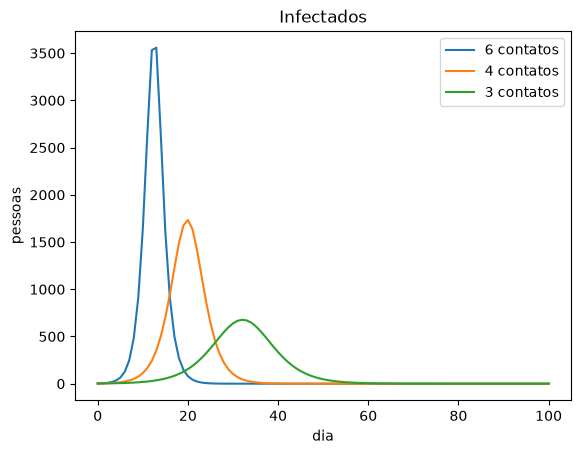

In [9]:
picos = []
fig, ax = plt.subplots()
for contatos in [6, 4, 3]:
    r = simular(SIR, passos=100, variaveis=variaveis_sir, contacts=contatos)
    r["infected"].plot(ax=ax, label=f"{contatos} contatos")
    picos.append({"contatos": contatos,
                  "pico (pessoas)": round(r["infected"].max()),
                  "dia do pico": r["infected"].idxmax(),
                  "nunca infectados": round(r["susceptible"].iloc[-1])})
ax.set(title="Infectados", xlabel="dia", ylabel="pessoas"); ax.legend()
pd.DataFrame(picos)

✏️ **Pergunta 3.** Além de baixar o pico, o que o distanciamento muda no número de pessoas que nunca se infectam? Por que isso é efeito da retroalimentação?

## 4. Dois estoques que dependem um do outro: predador e presa

As presas crescem sozinhas e morrem ao encontrar predadores; os predadores morrem sozinhos e crescem ao comer presas (modelo de Lotka-Volterra).

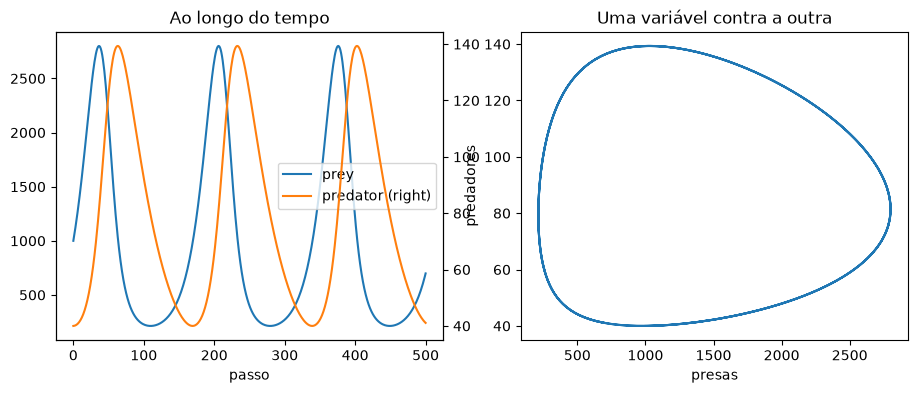

In [10]:
pp = simular(PredatorPrey, passos=500, variaveis=["prey", "predator"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
pp.plot(ax=a1, secondary_y="predator", title="Ao longo do tempo")
a2.plot(pp["prey"], pp["predator"]); a2.set(xlabel="presas", ylabel="predadores", title="Uma variável contra a outra");

As populações oscilam: muitas presas → os predadores crescem → as presas caem → os predadores caem → as presas voltam.

O equilíbrio, onde nada muda, vem das próprias taxas:

- presas = morte do predador / ganho por presa = 0,02 / 0,00002 = **1000**
- predadores = crescimento da presa / perda por predador = 0,08 / 0,001 = **80**

🔧 Comece exatamente no equilíbrio (`prey=1000, predator=80`) e depois um pouco fora dele (`prey=1000, predator=70`).

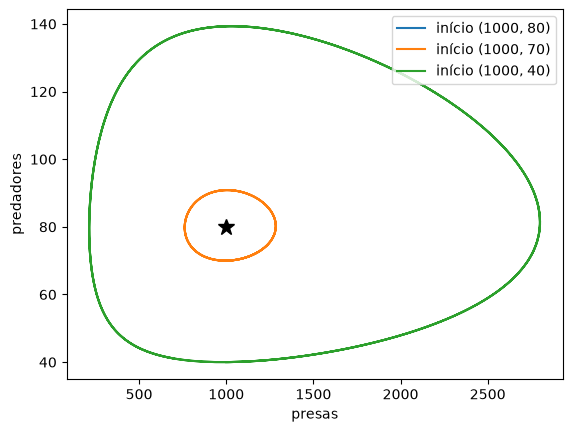

In [11]:
fig, ax = plt.subplots()
for presas, predadores in [(1000, 80), (1000, 70), (1000, 40)]:
    r = simular(PredatorPrey, 500, ["prey", "predator"], prey=presas, predator=predadores)
    ax.plot(r["prey"], r["predator"], label=f"início ({presas}, {predadores})")
ax.plot(1000, 80, "k*", markersize=12)
ax.set(xlabel="presas", ylabel="predadores"); ax.legend();

✏️ **Pergunta 4.** No modelo da floresta, começar fora do equilíbrio levava de volta a ele. Aqui, o que acontece? O que isso diz sobre usar um modelo para prever o futuro?

## 5. É o mesmo modelo do TerraME?

O `dissmodel-sysdyn` traduz os exemplos do pacote `sysdyn` do TerraME. Para conferir a tradução, guardamos a saída do TerraME para cada modelo (os *goldens*, no repositório `terrame-goldens`, versão 0.1.0) e comparamos.

Lemos a saída do SIR do TerraME direto do repositório:

In [12]:
URL = "https://raw.githubusercontent.com/LambdaGeo/terrame-goldens/v0.1.0/goldens/sysdyn/{}.csv.gz"
terrame = pd.read_csv(URL.format("sir")).set_index("step")
terrame.head()

,susceptible,infected,recovered,contacts
step,,,,
0,9998.000000,2.000000,0.000000,6
1,9995.000600,3.999400,1.000000,6
2,9989.004499,7.995801,2.999700,6
3,9977.023986,15.978414,6.997600,6
4,9953.111433,31.901760,14.986807,6


In [13]:
nosso = simular(SIR, passos=30, variaveis=variaveis_sir)
diferenca = (nosso - terrame[variaveis_sir]).abs()
print("maior diferença em cada variável:")
print(diferenca.max())
print("\nidênticos, número a número?", (nosso.values == terrame[variaveis_sir].values).all())

maior diferença em cada variável:
susceptible    0.0
infected       0.0
recovered      0.0
dtype: float64

idênticos, número a número? True


Diferença zero: os dois programas fazem as mesmas contas na mesma ordem. Isso não aconteceu de primeira. A ordem dos termos de uma soma muda o último dígito (lembre do encontro 4), e o código do DisSModel foi ajustado para seguir a ordem do TerraME.

🔧 Faça o mesmo para a banheira (`"tub"`, 8 passos, variável `water`) e para predador-presa (`"predator_prey"`, 500 passos, variáveis `prey` e `predator`).

In [14]:
casos = {"tub": (Tub, 8, ["water"]),
         "predator_prey": (PredatorPrey, 500, ["prey", "predator"])}
for nome, (Modelo, passos, vs) in casos.items():
    ref = pd.read_csv(URL.format(nome)).set_index("step")[vs]
    r = simular(Modelo, passos, vs)
    print(f"{nome:15s} maior diferença: {(r - ref).abs().max().max():.1e}   idênticos: {(r.values == ref.values).all()}")

tub             maior diferença: 0.0e+00   idênticos: True
predator_prey   maior diferença: 0.0e+00   idênticos: True


✏️ **Pergunta 5.** O modelo dá exatamente o mesmo número que o TerraME. Isso prova que o modelo SIR está **certo** para uma epidemia real?

## Para casa

1. No modelo `Floresta`, acrescente uma segunda saída: uma área fixa de 3 km² desmatada por ano para estradas, além da fração. Qual o novo equilíbrio? Escreva a conta antes de rodar.
2. No SIR, troque `duration` (dias de doença) de 2 para 4, com 6 contatos. O que muda no pico? Explique pela retroalimentação.
3. Escolha um processo da sua pesquisa e desenhe, à mão, seus estoques, fluxos e retroalimentações (diagrama de estoque e fluxo). Traga para o próximo encontro.